In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import json

# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)


In [6]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rf"]        
file_name = cfg["rf_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [7]:
from sklearn.model_selection import train_test_split 
X = data.drop(columns=[target])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 118 samples
Test set size: 30 samples


MAE (test): 0.23055179664077455
RMSE (test): 0.317176311624583
R² (test): 0.8996641012893261
 
MAE (train): 0.1232845932141677
RMSE (train): 0.1644051218643364
R² (train): 0.9729117841075612


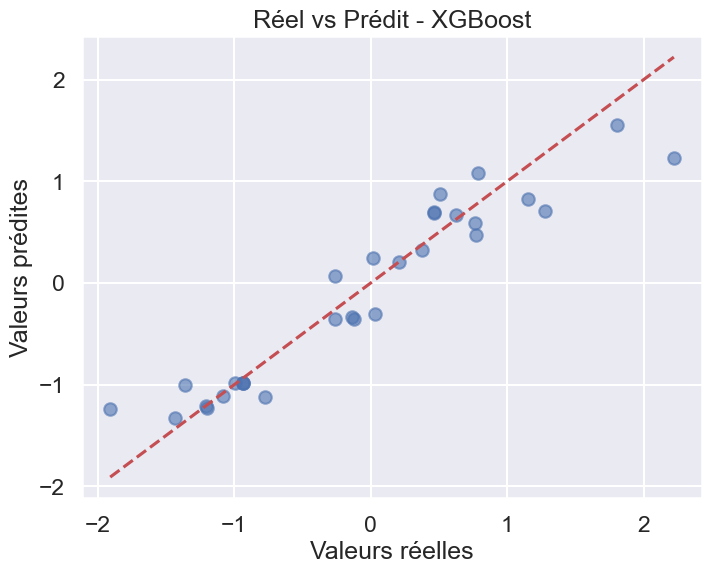

In [8]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialisation
model = XGBRegressor(
    max_depth=3,        # arbres moins profonds
    n_estimators=100,   # moins d'arbres
    learning_rate=0.1,
    subsample=0.8,      # échantillonnage aléatoire
    colsample_bytree=0.8,
    reg_alpha=0.1,      # régularisation L1
    reg_lambda=1.0      # régularisation L2
)

# Entraînement
model.fit(X_train, y_train)

# Prédiction sur le test set
y_pred = model.predict(X_test)



# Évaluation sur le test set
print("MAE (test):", mean_absolute_error(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² (test):", r2_score(y_test, y_pred))
print(" ")

#évaluation sur le train set 
print("MAE (train):", mean_absolute_error(y_train, model.predict(X_train)))
print("RMSE (train):", np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
print("R² (train):", r2_score(y_train, model.predict(X_train)))


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()



Fitting 10 folds for each of 864 candidates, totalling 8640 fits
Meilleurs paramètres: {'colsample_bytree': 0.6, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.5, 'reg_lambda': 5.0, 'subsample': 0.7}
Meilleur R² (CV): 0.8464574399451303

MAE (test): 0.24628639716333436
RMSE (test): 0.3412737641396503
R² (test): 0.8838389146335303
R² (train): 0.9575237895020962


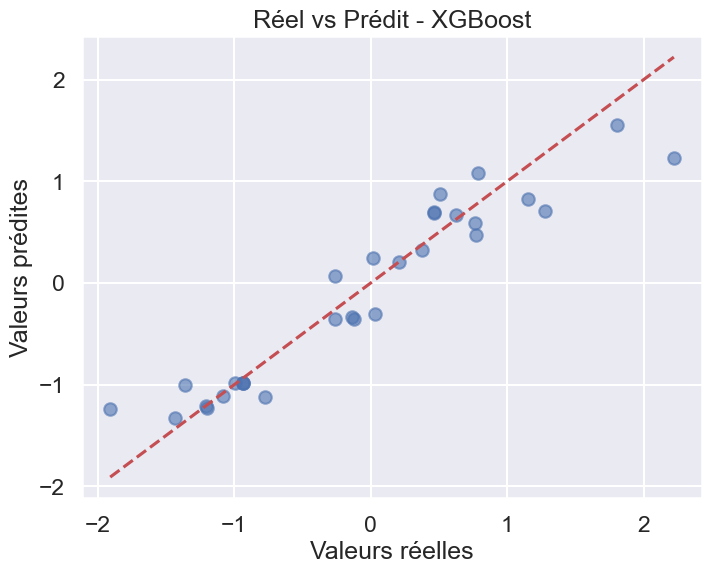

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 4],             # max_depth : profondeur max des arbres — plus bas = moins d'overfitting
    'n_estimators': [100, 200, 300], # n_estimators : nombre d'arbres — plus = plus précis mais plus lent
    'learning_rate': [0.01, 0.10],   # learning_rate : taille du pas à chaque arbre — plus bas = plus robuste mais besoin de plus d'arbres
    'subsample': [0.6, 0.7],         # subsample : fraction des lignes utilisées par arbre — moins de 1 = moins d'overfitting
    'colsample_bytree': [0.6, 0.7],  # colsample_bytree : fraction des colonnes utilisées par arbre — moins de 1 = moins d'overfitting
    'reg_alpha': [0.5, 1.0, 2.0],    # reg_alpha : régularisation L1 — pousse les poids vers 0, sélection de features
    'reg_lambda': [2.0, 5.0],        # reg_lambda : régularisation L2 — pénalise les grands poids, lisse le modèle
    'min_child_weight': [5, 10, 15], # min_child_weight : poids minimum pour créer un nœud — plus élevé = splits plus conservateurs
}

grid_search = GridSearchCV(
    XGBRegressor(),
    param_grid,
    cv=10,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres:", grid_search.best_params_)
print("Meilleur R² (CV):", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nMAE (test):", mean_absolute_error(y_test, y_pred_best))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R² (test):", r2_score(y_test, y_pred_best))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()


Le modèle XGBoost atteint un R² de 0.947 sur le jeu de test, ce qui constitue une performance solide. Cependant, avec seulement 148 échantillons, entraîner un modèle aussi complexe reste délicat, le manque de données augmente significativement le risque de surapprentissage, ce qui limite la capacité du modèle à généraliser sur de nouvelles observations.